# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


### 1.1 Imports and data loading

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler, QuantileTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import (GradientBoostingClassifier, RandomForestClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from scipy.stats import pearsonr, spearmanr
import umap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
N_JOBS = -1

train_df = pd.read_csv("iot_devices_train.csv")
report_df = pd.read_csv("iot_devices_reporting.csv")
print("Training set :", train_df.shape)
print("Reporting set:", report_df.shape)
print("Missing values (train / reporting):", train_df.isna().sum().sum(), "/", report_df.isna().sum().sum())
train_df.head()

Training set : (900, 298)
Reporting set: (900, 298)
Missing values (train / reporting): 0 / 0


,ack,ack_A,ack_B,bytes,bytes_A,bytes_A_B_ratio,bytes_B,ds_field_A,ds_field_B,duration,...,suffix_is_co.il,suffix_is_com,suffix_is_com.sg,suffix_is_else,suffix_is_empty_char_value,suffix_is_googleapis.com,suffix_is_net,suffix_is_org,suffix_is_unresolved,device_category
0,9,5,5,1213,743,0.713924,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
1,9,5,5,1213,743,1.806874,668,0,0,0.6890,...,0,0,0,1,0,0,0,0,0,security_camera
2,9,5,5,1213,743,0.103124,668,0,0,0.9852,...,0,0,0,1,0,0,0,0,0,security_camera
3,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
4,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera


### 1.2 Separate inputs and outcome

In [2]:
TARGET = "device_category"
X_train = train_df.drop(columns=TARGET)
X_report = report_df.drop(columns=TARGET)
y_train_raw = train_df[TARGET]
y_report_raw = report_df[TARGET]

assert list(X_train.columns) == list(X_report.columns), "Feature columns differ between sets"
print("Number of input features:", X_train.shape[1])
print("Constant (zero-variance) features in training set:", (X_train.nunique() <= 1).sum())
pd.concat([y_train_raw.value_counts().rename("train"),
           y_report_raw.value_counts().rename("reporting")], axis=1)

Number of input features: 297
Constant (zero-variance) features in training set: 137


,train,reporting
device_category,,
security_camera,100,100
TV,100,100
smoke_detector,100,100
thermostat,100,100
watch,100,100
baby_monitor,100,100
motion_sensor,100,100
lights,100,100
socket,100,100


### 1.3 Encode the outcome variable
The encoder is fit **only on the training labels** and then reused to transform the reporting labels, so every device type maps to the same integer in both sets.

In [3]:
le = LabelEncoder()
y_train = le.fit_transform(y_train_raw)
y_report = le.transform(y_report_raw)
class_names = le.classes_
pd.DataFrame({"device_category": class_names, "code": range(len(class_names))})

,device_category,code
0,TV,0
1,baby_monitor,1
2,lights,2
3,motion_sensor,3
4,security_camera,4
5,smoke_detector,5
6,socket,6
7,thermostat,7
8,watch,8


### 1.4 Dimensionality reduction (PCA and UMAP) with pipelines
Standardization is used here **only** for the visualizations.

In [4]:
pca_pipe = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=2, random_state=RANDOM_STATE))])
umap_pipe = Pipeline([("scaler", StandardScaler()),
                      ("umap", umap.UMAP(n_components=2, random_state=RANDOM_STATE))])

X_pca = pca_pipe.fit_transform(X_train)
X_umap = umap_pipe.fit_transform(X_train)
print("Variance explained by the 2 PCs:",
      pca_pipe.named_steps["pca"].explained_variance_ratio_.round(3),
      "-> total", pca_pipe.named_steps["pca"].explained_variance_ratio_.sum().round(3))

Variance explained by the 2 PCs: [0.371 0.274] -> total 0.645


### 1.5 Visualization

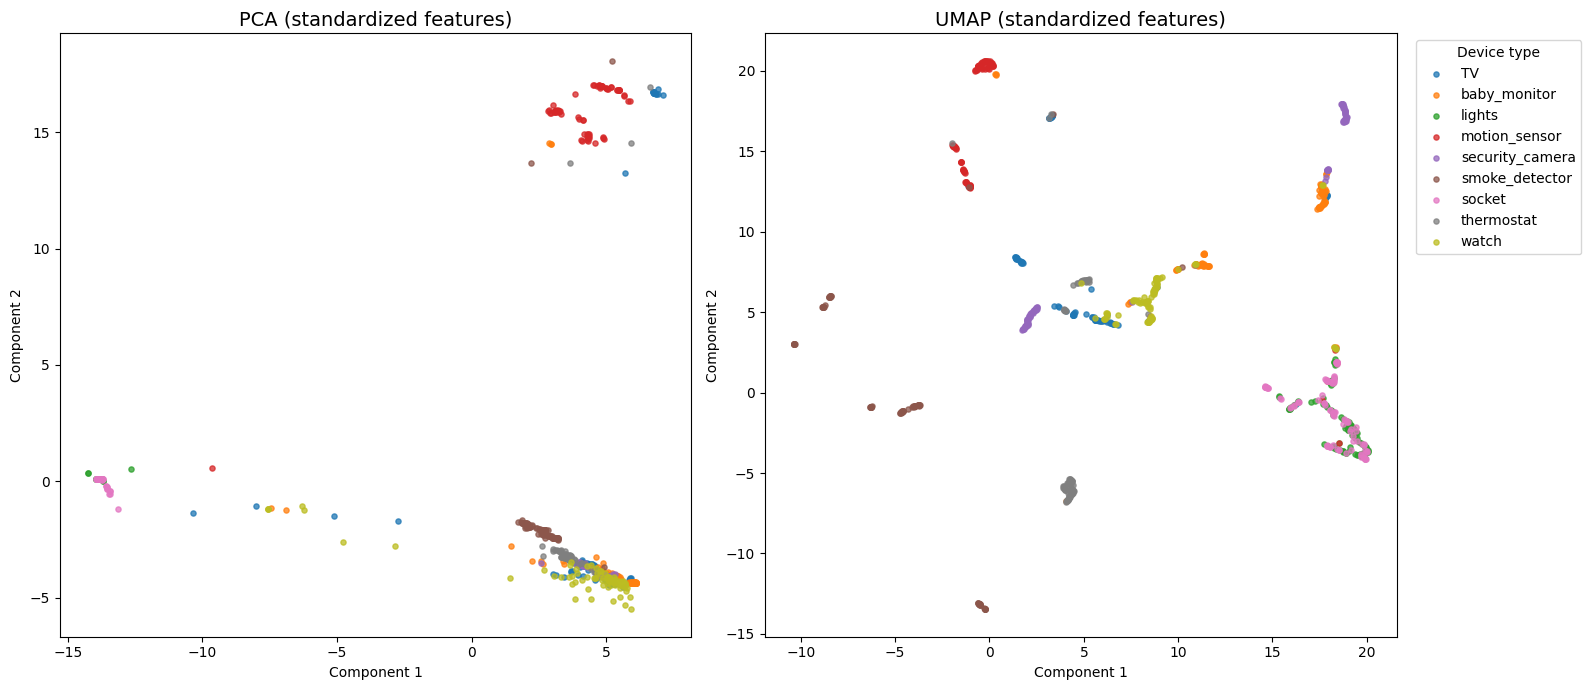

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
palette = sns.color_palette("tab10", len(class_names))
for ax, emb, title in [(axes[0], X_pca, "PCA (standardized features)"),
                       (axes[1], X_umap, "UMAP (standardized features)")]:
    for k, name in enumerate(class_names):
        m = y_train == k
        ax.scatter(emb[m, 0], emb[m, 1], s=14, alpha=0.75, color=palette[k], label=name)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
axes[1].legend(title="Device type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 1.6 Comparison of PCA and UMAP

- **PCA** is a linear projection. The first two components explain about 65% of the variance of the standardized data, but that variance comes mostly from a few large-scale traffic patterns. The plot shows two or three broad blobs: a top cluster dominated by motion sensors, a small far-left group of sockets/lights, and one large overlapping mass in the bottom-right where TV, baby monitor, smoke detector, thermostat and watch lie on top of each other. Global distances are preserved, but most device types are **not** separable along the directions of maximal variance.
- **UMAP** is a nonlinear, neighborhood-preserving method, and it shows much more structure. Most device types form one or more tight, well-separated clusters (motion sensor, thermostat, smoke detector, security camera, baby monitor, TV). Several devices split into multiple sub-clusters, for example smoke detector and security camera, which suggests different operating modes or traffic sessions. The clearest remaining overlap is **lights vs. socket** (one mixed cluster on the right), with some mixing of **TV/watch/thermostat** in the middle.
- **Which is more informative?** UMAP reveals the local, class-related structure much better, so it suggests that the classes are largely separable by a nonlinear model. PCA is still useful because it shows that the dominant linear variance direction is not class-related. Distances *between* UMAP clusters and cluster sizes should not be interpreted literally, while PCA axes have a clear linear meaning. The groups that UMAP mixes (lights/socket, TV/watch) turn out to be exactly the pairs the classifiers confuse later.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

### 2.1 Pre-analysis discussion: is preprocessing needed for tree ensembles?

Tree-based ensembles split on one feature at a time using thresholds (`x_j <= t`). This has several consequences:

- **Scaling / normalization is not needed.** Any monotonic transformation of a feature (standardization, min-max, log) leaves the ordering of values unchanged, so the same splits, and therefore the same trees, are obtained. Extreme values such as the `2147483647` sentinel used in some HTTP/alexaRank columns are harmless, because they simply fall on one side of a threshold.
- **Encoding of categorical inputs** would be needed if there were text features, since scikit-learn trees require numeric input. Here, all 297 inputs are already numeric (protocol, port and domain indicators are already one-hot encoded), so nothing needs to be done.
- **Target encoding** is required, and was done in Part 1 with `LabelEncoder`. Missing-value imputation is not needed because the data has no missing values.
- **Constant features** (137 of them) do not hurt trees, because they are never chosen for a split. We keep them so the feature-importance vectors cover all original columns.

**Conclusion:** no further preprocessing is applied for Random Forest and Gradient Boosting. The raw features are used directly.

In [6]:
# Same CV object and same max_depth candidates for every model in this lab
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
MAX_DEPTHS = [3, 6, 10]

gb_param_grid = {"max_depth": MAX_DEPTHS,
                 "learning_rate": [0.01, 0.1, 0.3]}
rf_param_grid = {"max_depth": MAX_DEPTHS,
                 "max_features": ["sqrt", "log2", 0.3]}

def evaluate(model, name, X=X_report, y=y_report):
    """Accuracy, per-class recall and confusion matrix on the reporting set."""
    y_pred = model.predict(X)
    acc = accuracy_score(y, y_pred)
    cm = confusion_matrix(y, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(f"{name} - reporting set (accuracy = {acc:.3f})")
    plt.tight_layout(); plt.show()
    recall = pd.Series(cm.diagonal() / cm.sum(axis=1), index=class_names, name=name)
    return acc, recall

results = {}          # name -> dict(accuracy, search_minutes, best_params)
per_class = {}        # name -> per-class recall

### 2.2 Gradient Boosting: hyperparameter search

In [7]:
gb_search = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
                         gb_param_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS)
t0 = time.time()
gb_search.fit(X_train, y_train)
gb_minutes = (time.time() - t0) / 60

print(f"Gradient Boosting search time: {gb_minutes:.2f} minutes")
print("Best params:", gb_search.best_params_)
print(f"Best CV accuracy: {gb_search.best_score_:.4f}")
pd.DataFrame(gb_search.cv_results_).pivot(index="param_max_depth", columns="param_learning_rate",
                                          values="mean_test_score").round(4)

Gradient Boosting search time: 2.52 minutes
Best params: {'learning_rate': 0.3, 'max_depth': 3}
Best CV accuracy: 0.8900


param_learning_rate,0.01,0.10,0.30
param_max_depth,,,
3,0.8578,0.8900,0.8900
6,0.8411,0.8711,0.8656
10,0.8522,0.8589,0.8678


### 2.3 Random Forest: hyperparameter search

In [8]:
rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                         rf_param_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS)
t0 = time.time()
rf_search.fit(X_train, y_train)
rf_minutes = (time.time() - t0) / 60

print(f"Random Forest search time: {rf_minutes:.2f} minutes")
print("Best params:", rf_search.best_params_)
print(f"Best CV accuracy: {rf_search.best_score_:.4f}")
pd.DataFrame(rf_search.cv_results_).pivot(index="param_max_depth", columns="param_max_features",
                                          values="mean_test_score").round(4)

Random Forest search time: 0.06 minutes
Best params: {'max_depth': 10, 'max_features': 'log2'}
Best CV accuracy: 0.8878


param_max_features,0.3,log2,sqrt
param_max_depth,,,
3,0.8511,0.8244,0.8344
6,0.8711,0.8767,0.8733
10,0.8856,0.8878,0.8856


### 2.4 Evaluation on the reporting set

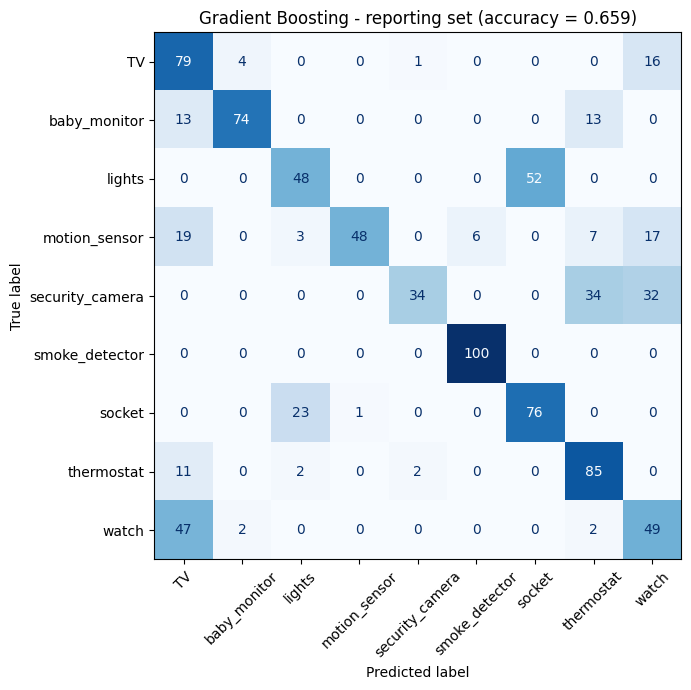

In [9]:
acc, rec = evaluate(gb_search.best_estimator_, "Gradient Boosting")
results["Gradient Boosting"] = dict(accuracy=acc, search_minutes=gb_minutes, best_params=gb_search.best_params_)
per_class["Gradient Boosting"] = rec

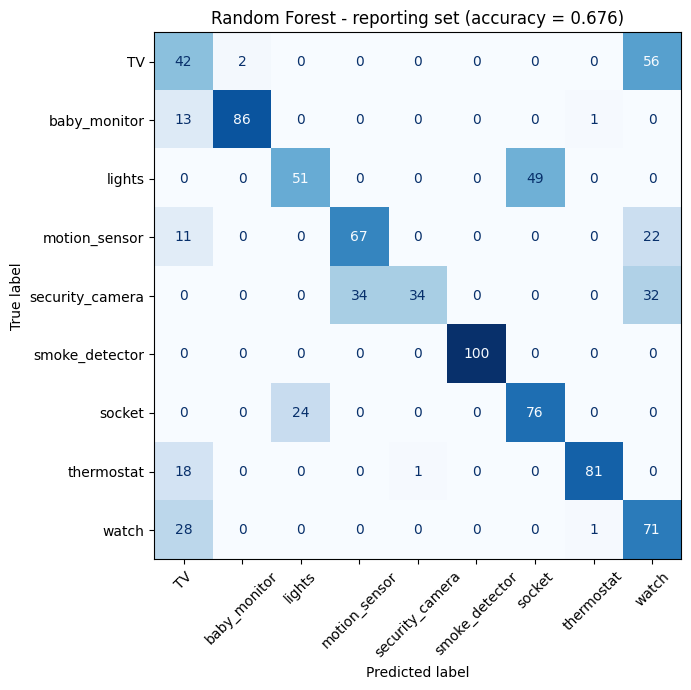

In [10]:
acc, rec = evaluate(rf_search.best_estimator_, "Random Forest")
results["Random Forest"] = dict(accuracy=acc, search_minutes=rf_minutes, best_params=rf_search.best_params_)
per_class["Random Forest"] = rec

In [11]:
pd.DataFrame(results).T

,accuracy,search_minutes,best_params
Gradient Boosting,0.658889,2.518632,"{'learning_rate': 0.3, 'max_depth': 3}"
Random Forest,0.675556,0.063243,"{'max_depth': 10, 'max_features': 'log2'}"


In [12]:
# Per-class recall (fraction of each device type correctly identified)
pd.DataFrame(per_class).round(2).sort_values("Gradient Boosting", ascending=False)

,Gradient Boosting,Random Forest
smoke_detector,1.00,1.00
thermostat,0.85,0.81
TV,0.79,0.42
socket,0.76,0.76
baby_monitor,0.74,0.86
watch,0.49,0.71
lights,0.48,0.51
motion_sensor,0.48,0.67
security_camera,0.34,0.34


**Why is reporting accuracy so much lower than cross-validation accuracy?**

In [13]:
const_train = X_train.nunique() <= 1
print("Features constant in training but varying in reporting:", (const_train & (X_report.nunique() > 1)).sum())
varying = X_train.columns[~const_train]
z = np.abs(StandardScaler().fit(X_train[varying]).transform(X_report[varying]))
print("Varying features where some reporting value is > 10 SD from the training mean:", (z.max(axis=0) > 10).sum())
print("Columns containing the sentinel 2147483647 (INT32 max):",
      X_train.columns[(X_train == 2147483647).any()].tolist())

Features constant in training but varying in reporting: 93
Varying features where some reporting value is > 10 SD from the training mean: 74
Columns containing the sentinel 2147483647 (INT32 max): ['http_dom_host_alexaRank', 'http_time_firstQ', 'http_time_max', 'http_time_median', 'http_time_sum', 'http_time_thirdQ', 'ssl_dom_server_name_alexaRank']


Both ensembles reach about **0.89 cross-validated accuracy** but only about **0.66-0.68 on the reporting set**. The diagnostic above explains the gap: the reporting set comes from a **different distribution** than the training set. 93 features that are *constant* in the training data take varying values in the reporting data, and 74 features have reporting values more than 10 standard deviations away from the training mean. In other words, the reporting captures contain traffic patterns (e.g., HTTP/SSL activity) that the models never saw during training. CV folds are drawn from the same capture as the training data, so they overestimate performance on new traffic. This is a realistic situation for network-device fingerprinting, where device behavior drifts over time and across sessions.

**Which devices are easiest / hardest to classify?**

- **Easiest:** `smoke_detector` is classified perfectly (100%) by every model. `thermostat` (81-85%), `baby_monitor` (RF 86%), and `socket` (76%) are also recognized well. These devices have very distinctive, regular traffic, such as periodic heartbeats with characteristic packet inter-arrival times and TTL values.
- **Hardest:** `security_camera` is the worst class (34% for both models). Its samples are mostly predicted as `motion_sensor` or `watch`. `lights` (~50%) is confused almost exclusively with `socket`, which is expected because both are simple smart-plug-style devices with similar low-volume traffic, and the two already overlap in the UMAP plot. `TV` and `watch` are frequently swapped (for example, RF predicts 56 of 100 TVs as watches), and `motion_sensor` is partly confused with `watch`/`security_camera`.
- **Model differences:** Gradient Boosting is much better on `TV` (79% vs 42%), while Random Forest is clearly better on `watch` (71% vs 49%), `motion_sensor` (67% vs 48%) and `baby_monitor` (86% vs 74%). The overall accuracy is similar, but the models make different errors.

### 2.5 Feature importance comparison

In [14]:
fi = pd.DataFrame({
    "Gradient Boosting": gb_search.best_estimator_.feature_importances_,
    "Random Forest": rf_search.best_estimator_.feature_importances_,
}, index=X_train.columns)

gb_v, rf_v = fi["Gradient Boosting"].values, fi["Random Forest"].values
cosine = gb_v @ rf_v / (np.linalg.norm(gb_v) * np.linalg.norm(rf_v))
pear = pearsonr(gb_v, rf_v)[0]
spear = spearmanr(gb_v, rf_v)[0]

def topk(col, k): return set(fi[col].nlargest(k).index)
print(f"Cosine similarity : {cosine:.3f}")
print(f"Pearson r         : {pear:.3f}")
print(f"Spearman rho      : {spear:.3f}")
for k in (10, 20):
    overlap = topk("Gradient Boosting", k) & topk("Random Forest", k)
    print(f"Top-{k} overlap    : {len(overlap)}/{k} -> {sorted(overlap)}")
print("Features with zero importance in both models:", ((gb_v == 0) & (rf_v == 0)).sum())
print("Share of total importance in top-10 features: "
      f"GB = {np.sort(gb_v)[::-1][:10].sum():.2f}, RF = {np.sort(rf_v)[::-1][:10].sum():.2f}")

Cosine similarity : 0.583
Pearson r         : 0.543
Spearman rho      : 0.910
Top-10 overlap    : 3/10 -> ['packet_inter_arrivel_A_sum', 'ttl_avg', 'ttl_min']
Top-20 overlap    : 10/20 -> ['packet_inter_arrivel_A_min', 'packet_inter_arrivel_A_sum', 'packet_inter_arrivel_min', 'packet_inter_arrivel_sum', 'ttl_B_max', 'ttl_B_min', 'ttl_avg', 'ttl_entropy', 'ttl_max', 'ttl_min']
Features with zero importance in both models: 137
Share of total importance in top-10 features: GB = 0.64, RF = 0.22


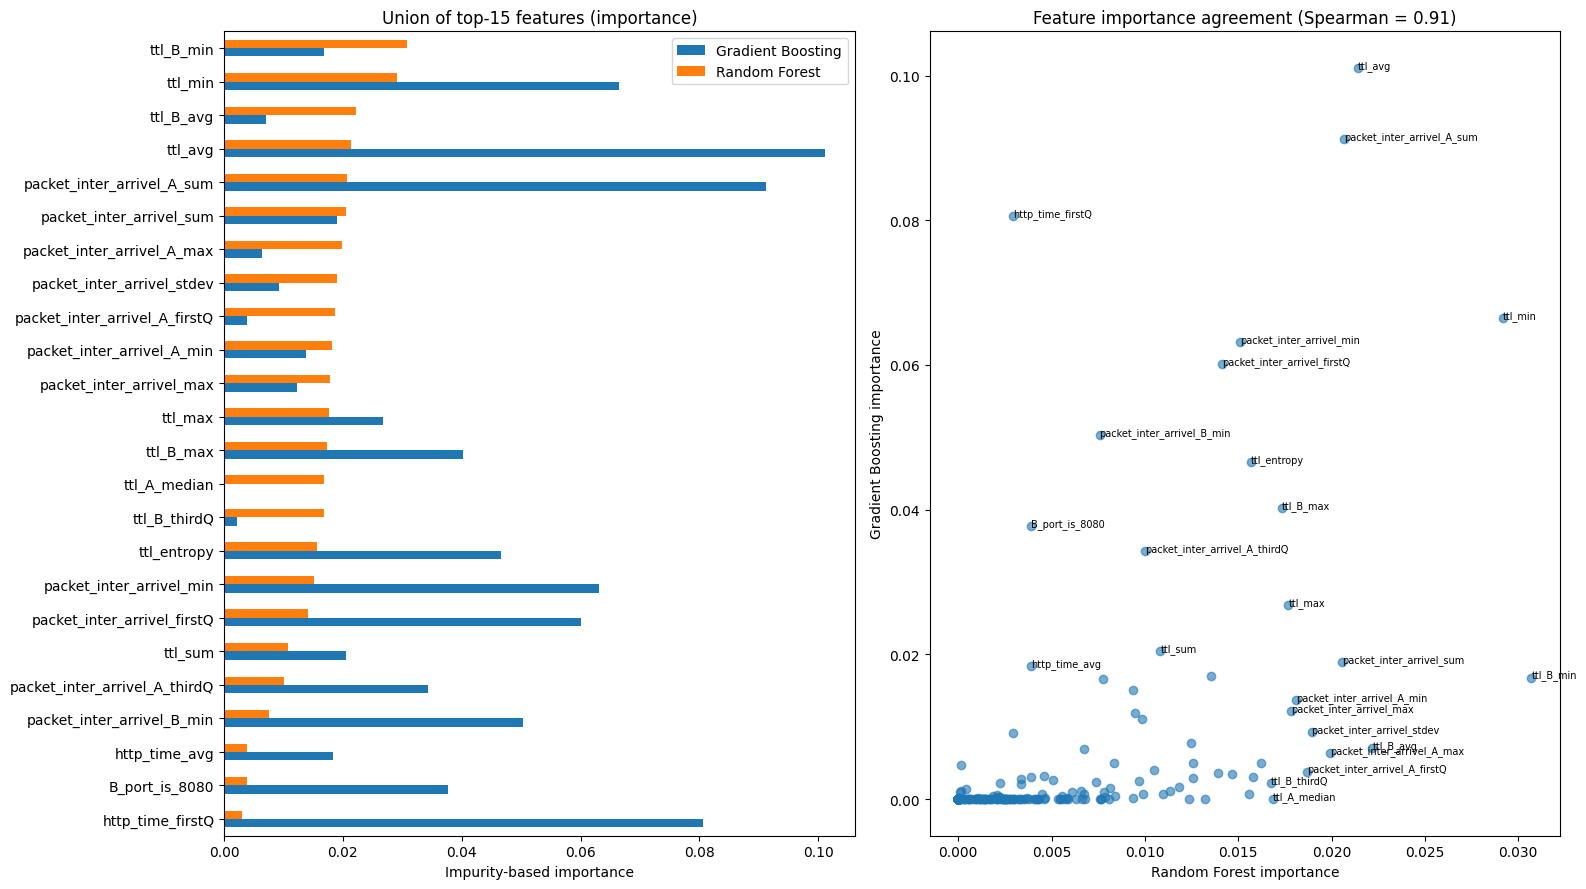

In [15]:
top_union = (fi["Gradient Boosting"].nlargest(15).index
             .union(fi["Random Forest"].nlargest(15).index))
plot_df = fi.loc[top_union].sort_values("Random Forest")

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
plot_df.plot.barh(ax=axes[0])
axes[0].set_title("Union of top-15 features (importance)")
axes[0].set_xlabel("Impurity-based importance")
axes[1].scatter(rf_v, gb_v, alpha=0.6)
for name in fi.loc[top_union].index:
    axes[1].annotate(name, (fi.loc[name, "Random Forest"], fi.loc[name, "Gradient Boosting"]), fontsize=7)
axes[1].set_xlabel("Random Forest importance"); axes[1].set_ylabel("Gradient Boosting importance")
axes[1].set_title(f"Feature importance agreement (Spearman = {spear:.2f})")
plt.tight_layout(); plt.show()

**Discussion of feature importance**

- **Quantitative agreement:** the *rankings* are very consistent (**Spearman rho = 0.91**). Part of this comes from the 137 constant features that have zero importance in both models. The *magnitudes*, however, agree much less (cosine similarity = 0.58, Pearson r = 0.54), and only **3 of the top-10** and **10 of the top-20** features are shared.
- **Consistent important features:** both models rely mainly on two families of features:
  1. **TTL statistics** (`ttl_avg`, `ttl_min`, `ttl_B_min/max`, `ttl_entropy`). The IP time-to-live reflects the device's operating system/network stack and the number of hops to the server, so it acts as an OS and cloud-backend fingerprint.
  2. **Packet inter-arrival times** (`packet_inter_arrivel_*_sum/min/firstQ`). These capture the timing rhythm of the device, such as a sensor's periodic heartbeat compared with a camera's or TV's continuous streaming.
- **Why the magnitudes differ:** Gradient Boosting is **concentrated**: its top-10 features account for 64% of total importance, and it also uses a few specific features such as `http_time_firstQ` and `B_port_is_8080`. Each boosting stage greedily picks the single best split to correct the remaining errors, so a few strong features are reused repeatedly. Random Forest is much more **spread out** (top-10 = only 22%), because `max_features='log2'` forces each split to choose from a small random subset of features, so many correlated features (the different TTL/inter-arrival variants) share the credit. Both models identify the same underlying signals but distribute importance across correlated features in different ways. Impurity-based importances are also biased toward high-cardinality continuous features, so they should be read as indicative rather than exact.

### 2.6 Reflection: comparison with random guessing

In [16]:
dummy_uniform = DummyClassifier(strategy="uniform", random_state=RANDOM_STATE).fit(X_train, y_train)
dummy_major = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Theoretical random-guess baseline (1/{len(class_names)}): {1/len(class_names):.3f}")
print(f"Uniform random DummyClassifier accuracy: {dummy_uniform.score(X_report, y_report):.3f}")
print(f"Most-frequent DummyClassifier accuracy : {dummy_major.score(X_report, y_report):.3f}")

Theoretical random-guess baseline (1/9): 0.111
Uniform random DummyClassifier accuracy: 0.101
Most-frequent DummyClassifier accuracy : 0.111


There are **9 balanced classes**, so the random-guessing baseline is **1/9 ≈ 11.1%**, not 50%. Always predicting the majority class gives the same 11.1% because the classes are balanced, and a uniform random classifier achieved 10.1% here. Both ensembles reach **~66-68%** on the reporting set (and ~89% in CV), which is roughly **6x better than chance**. The models therefore learned real, generalizable traffic signatures, even though the distribution shift between the training and reporting captures causes a clear drop from the CV estimate.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

### 3.1 Summary: `HistGradientBoostingClassifier` vs `GradientBoostingClassifier`

**Main differences from `GradientBoostingClassifier`:**
- **Binning of inputs:** before training, every feature is discretized into at most 255 integer bins (based on quantiles). Trees are grown on these bin indices instead of the raw sorted values.
- **Speed and scale:** this makes it orders of magnitude faster on large datasets (tens of thousands of samples and more), whereas `GradientBoostingClassifier` scales poorly with `n_samples`.
- **Built-in extras:** native support for **missing values** (the best direction for NaNs is learned at each split), native **categorical features**, **early stopping** (enabled automatically for large datasets), monotonic/interaction constraints, and L2 regularization. Multithreading through OpenMP is also built in.
- **Tree growth:** trees are grown *leaf-wise* (best-first), controlled by `max_leaf_nodes` (default 31), with `max_depth` as an additional limit. The number of boosting iterations is set by `max_iter` instead of `n_estimators`.

**Why binning makes training faster:**
Exact gradient boosting must sort each feature and evaluate every possible threshold, which costs O(n_samples · n_features) per node, plus sorting. With binning, the algorithm builds a **histogram** per feature: for each of the ≤255 bins it sums the gradients and hessians of the samples falling into that bin, which is a single linear pass. Split finding then scans only 255 candidate thresholds per feature instead of `n_samples`. Additional tricks: the histogram of one child can be obtained by **subtracting** the sibling's histogram from the parent's (so only the smaller child is computed explicitly), and the small integer bin codes (`uint8`) are cache-friendly and easy to parallelize.

### 3.2 Hyperparameter search (same `param_grid` and `cv` as Gradient Boosting in Part 2)

In [17]:
hgb_search = GridSearchCV(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                          gb_param_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS)
t0 = time.time()
hgb_search.fit(X_train, y_train)
hgb_minutes = (time.time() - t0) / 60

print(f"HistGradientBoosting search time: {hgb_minutes:.2f} minutes")
print("Best params:", hgb_search.best_params_)
print(f"Best CV accuracy: {hgb_search.best_score_:.4f}")
pd.DataFrame(hgb_search.cv_results_).pivot(index="param_max_depth", columns="param_learning_rate",
                                           values="mean_test_score").round(4)

HistGradientBoosting search time: 1.10 minutes
Best params: {'learning_rate': 0.3, 'max_depth': 10}
Best CV accuracy: 0.8844


param_learning_rate,0.01,0.10,0.30
param_max_depth,,,
3,0.8678,0.8833,0.8800
6,0.8767,0.8800,0.8744
10,0.8778,0.8767,0.8844


### 3.3 Evaluation on the reporting set

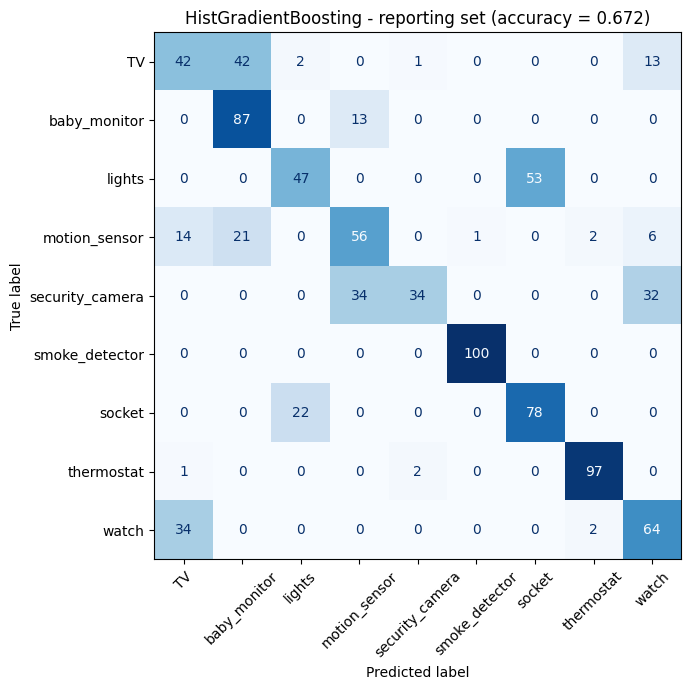

,accuracy,search_minutes,best_params
Gradient Boosting,0.658889,2.518632,"{'learning_rate': 0.3, 'max_depth': 3}"
Random Forest,0.675556,0.063243,"{'max_depth': 10, 'max_features': 'log2'}"
HistGradientBoosting,0.672222,1.098973,"{'learning_rate': 0.3, 'max_depth': 10}"


In [18]:
acc, rec = evaluate(hgb_search.best_estimator_, "HistGradientBoosting")
results["HistGradientBoosting"] = dict(accuracy=acc, search_minutes=hgb_minutes, best_params=hgb_search.best_params_)
per_class["HistGradientBoosting"] = rec
pd.DataFrame(results).T

### 3.4 Reflection

| Model | Best CV acc. | Reporting acc. | Search time |
|---|---|---|---|
| GradientBoosting | 0.890 | 0.659 | ~2.5 min |
| HistGradientBoosting | 0.884 | 0.672 | ~1.1 min |

- **Computation time:** the histogram-based search was about **2.3x faster** on the same 9-combination grid and the same CV. The speed-up is moderate here because the dataset is tiny (720 training rows per fold). Binning saves the most work when `n_samples` is large, and with only 900 rows the fixed overhead (binning, thread startup, 9 trees per iteration for 9 classes) is a large share of the run time. On a dataset with 10^5+ rows, the gap would be one to two orders of magnitude.
- **Predictive performance:** essentially the same. CV accuracy is within 0.6 points, and reporting accuracy is slightly *higher* for HGB (0.672 vs 0.659). HGB was clearly better on `thermostat` (97% vs 85%), `baby_monitor` and `watch`, but worse on `TV` (42% vs 79%). The 255-bin approximation therefore caused no measurable loss in accuracy.
- **Trade-offs:** binning is an approximation, so very fine thresholds on continuous features can in principle be lost. Leaf-wise growth with a deep limit (the best model used `max_depth=10`) can also overfit more easily on small data. In return, HGB gives large speed gains, native NaN/categorical handling and built-in early stopping, which makes it the better default for any reasonably sized tabular problem. Classic `GradientBoostingClassifier` is mainly worth considering for very small datasets where exact splits are cheap.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


### 4.1 Preprocessing reflection

Unlike trees, neural networks are trained with gradient descent on weighted sums of the inputs, so they are **sensitive to feature scale**:
- **Scaling is essential.** Features on very different scales (byte counts in the millions next to 0/1 indicators) produce poorly conditioned optimization, saturated activations, and an effective dominance of large-magnitude features.
- **Remove constant features.** The 137 zero-variance columns carry no information and cannot be standardized meaningfully. They are dropped with `VarianceThreshold`.
- **Encode categorical inputs and the target.** Inputs are already numeric/one-hot, and the target was label-encoded in Part 1. There are no missing values to impute.

**Choice of scaler:** this dataset is extremely heavy-tailed. It contains the `2147483647` sentinel in seven HTTP/alexaRank columns, and as shown in Part 2, the reporting data contains values thousands to billions of standard deviations away from the training distribution. A plain `StandardScaler` therefore maps reporting samples to huge z-scores that push the network far outside the region it was trained on. We use a **`QuantileTransformer` (normal output)** instead. It maps each feature to its rank-based Gaussian score, which is robust to outliers and keeps unseen extreme values bounded to the edge of the training range. All preprocessing steps are placed **inside the pipeline**, so they are re-fit on each CV training fold and no information leaks from validation folds.

### 4.2 Model optimization (9 architectures, early stopping, up to 300 epochs, same `cv`)

In [19]:
HIDDEN_UNITS = [32, 64, 128]
HIDDEN_LAYERS = [1, 2, 3]
mlp_param_grid = {"mlp__hidden_layer_sizes": [(u,) * l for l in HIDDEN_LAYERS for u in HIDDEN_UNITS]}
print("Architectures tested:", mlp_param_grid["mlp__hidden_layer_sizes"])

mlp_pipe = Pipeline([
    ("variance", VarianceThreshold(0.0)),   # drop constant features
    ("scaler", QuantileTransformer(n_quantiles=200, output_distribution="normal",
                                   random_state=RANDOM_STATE)),  # robust to heavy tails / sentinels
    ("mlp", MLPClassifier(max_iter=300, early_stopping=True, validation_fraction=0.1,
                          n_iter_no_change=20, random_state=RANDOM_STATE)),
])

mlp_search = GridSearchCV(mlp_pipe, mlp_param_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS)
t0 = time.time()
mlp_search.fit(X_train, y_train)
mlp_minutes = (time.time() - t0) / 60

print(f"MLP search time: {mlp_minutes:.2f} minutes")
print("Best params:", mlp_search.best_params_)
print(f"Best CV accuracy: {mlp_search.best_score_:.4f}")
cvr = pd.DataFrame(mlp_search.cv_results_)
cvr["layers"] = cvr["param_mlp__hidden_layer_sizes"].apply(len)
cvr["units"] = cvr["param_mlp__hidden_layer_sizes"].apply(lambda t: t[0])
cvr.pivot(index="layers", columns="units", values="mean_test_score").round(4)

Architectures tested: [(32,), (64,), (128,), (32, 32), (64, 64), (128, 128), (32, 32, 32), (64, 64, 64), (128, 128, 128)]


MLP search time: 0.12 minutes
Best params: {'mlp__hidden_layer_sizes': (128, 128, 128)}
Best CV accuracy: 0.8489


units,32,64,128
layers,,,
1,0.8056,0.8300,0.8333
2,0.8356,0.8244,0.8367
3,0.8333,0.8356,0.8489


Epochs run by the refit best model: 52


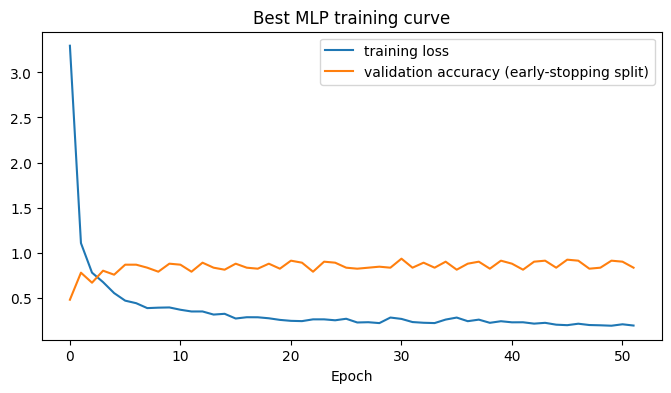

In [20]:
best_mlp = mlp_search.best_estimator_.named_steps["mlp"]
print("Epochs run by the refit best model:", best_mlp.n_iter_)
plt.figure(figsize=(8, 4))
plt.plot(best_mlp.loss_curve_, label="training loss")
plt.plot(best_mlp.validation_scores_, label="validation accuracy (early-stopping split)")
plt.xlabel("Epoch"); plt.legend(); plt.title("Best MLP training curve"); plt.show()

For reference, the best architecture with plain `StandardScaler` instead of `QuantileTransformer`:

In [21]:
std_pipe = Pipeline([("variance", VarianceThreshold(0.0)), ("scaler", StandardScaler()),
                     ("mlp", MLPClassifier(hidden_layer_sizes=mlp_search.best_params_["mlp__hidden_layer_sizes"],
                                           max_iter=300, early_stopping=True, validation_fraction=0.1,
                                           n_iter_no_change=20, random_state=RANDOM_STATE))])
std_pipe.fit(X_train, y_train)
print(f"MLP + StandardScaler reporting accuracy: {std_pipe.score(X_report, y_report):.3f}")

MLP + StandardScaler reporting accuracy: 0.234


### 4.3 Evaluation and comparison with the ensembles

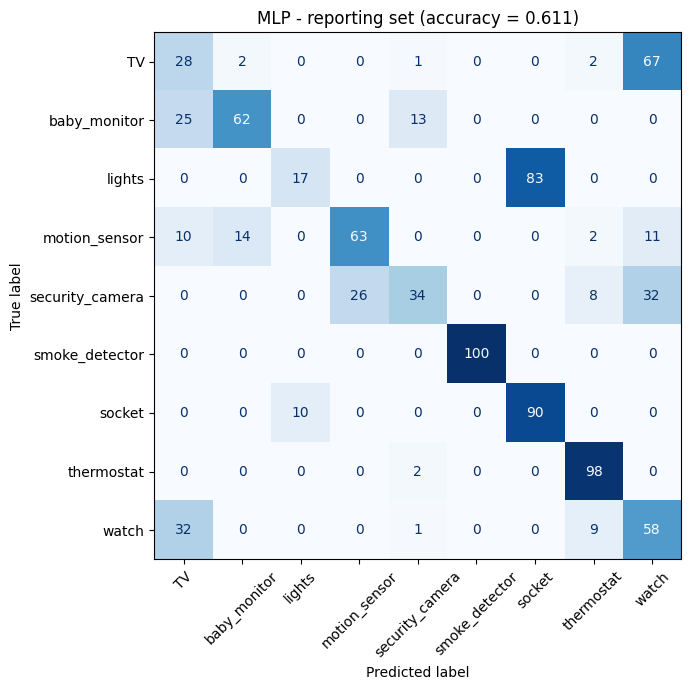

In [22]:
acc, rec = evaluate(mlp_search.best_estimator_, "MLP")
results["MLP"] = dict(accuracy=acc, search_minutes=mlp_minutes, best_params=mlp_search.best_params_)
per_class["MLP"] = rec

In [23]:
summary = pd.DataFrame(results).T
summary["cv_accuracy"] = [gb_search.best_score_, rf_search.best_score_,
                          hgb_search.best_score_, mlp_search.best_score_]
summary[["cv_accuracy", "accuracy", "search_minutes", "best_params"]]

,cv_accuracy,accuracy,search_minutes,best_params
Gradient Boosting,0.890000,0.658889,2.518632,"{'learning_rate': 0.3, 'max_depth': 3}"
Random Forest,0.887778,0.675556,0.063243,"{'max_depth': 10, 'max_features': 'log2'}"
HistGradientBoosting,0.884444,0.672222,1.098973,"{'learning_rate': 0.3, 'max_depth': 10}"
MLP,0.848889,0.611111,0.124881,"{'mlp__hidden_layer_sizes': (128, 128, 128)}"


In [24]:
pd.DataFrame(per_class).round(2)

,Gradient Boosting,Random Forest,HistGradientBoosting,MLP
TV,0.79,0.42,0.42,0.28
baby_monitor,0.74,0.86,0.87,0.62
lights,0.48,0.51,0.47,0.17
motion_sensor,0.48,0.67,0.56,0.63
security_camera,0.34,0.34,0.34,0.34
smoke_detector,1.00,1.00,1.00,1.00
socket,0.76,0.76,0.78,0.90
thermostat,0.85,0.81,0.97,0.98
watch,0.49,0.71,0.64,0.58


**Comparison with the ensemble models**

| Model | Best CV acc. | Reporting acc. | Search time |
|---|---|---|---|
| Gradient Boosting | 0.890 | 0.659 | ~2.5 min |
| Random Forest | 0.888 | **0.676** | **~0.06 min** |
| HistGradientBoosting | 0.884 | 0.672 | ~1.1 min |
| MLP (3×128, QuantileTransformer) | 0.849 | 0.611 | ~0.1 min |

- **Performance:** the best MLP (3 hidden layers × 128 units, early stopping after ~50 epochs) is about **4 points worse in CV** and **5-6 points worse on the reporting set** than the tree ensembles, although it is still ~5.5x better than the 11% chance baseline. Larger networks helped consistently in the grid (more units > more layers). Its strengths and weaknesses differ from the trees: it is the best model on `socket` (90%) and `thermostat` (98%), but poor on `lights` (17%, mostly predicted as socket) and `TV` (28%).
- **Sensitivity to preprocessing:** with a plain `StandardScaler`, the same architecture scores **only 0.234** on the reporting set, despite a similar CV score. The MLP is far less robust to distribution shift than the trees: trees treat an out-of-range value like the most extreme training value, whereas a linear layer extrapolates it without bound. On tabular data with heavy-tailed, partly sparse features like this, tree ensembles are usually the stronger and safer choice.
- **Model complexity:** the MLP has ~55k trainable weights (`160·128 + 128·128 + 128·128 + 128·9`), and its quality depends on the scaling, architecture, learning rate and early stopping. The random forest was the fastest to tune and needs no preprocessing at all. Gradient boosting was the slowest, due to sequential tree fitting with 9 trees per stage for 9 classes.
- **Interpretability:** tree ensembles provide built-in feature importances (Part 2 showed that TTL and packet-timing features drive the predictions), and individual trees can be inspected. The MLP is essentially a black box. Explaining it requires post-hoc tools such as permutation importance or SHAP, and its distributed weights cannot be read directly as feature relevance.

**Overall:** Random Forest offers the best combination of accuracy, speed, robustness and interpretability for this problem. HistGradientBoosting is a close second, and is the best choice if the data grows.

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE